# 2. Training the classifier

Fine-tunes... doesn't, actually. Trains a linear head on **frozen DINOv2
features**, the same frugal-AI approach validated on the nudibranch
project: with only ~1,550 lesions and five diagnoses after dropping the
two too-sparse classes, there is not enough data to safely fine-tune a
network from scratch without either overfitting or wasting most of its
capacity relearning generic visual features a much larger dataset already
taught a foundation model. Reusing that pretraining and training only a
small head on top is faster, and -- on the equivalent nudibranch
comparison -- was also more accurate than fine-tuning a small CNN from
scratch on a similarly small dataset.

That comparison does not automatically carry over to melanoma diagnosis,
which is a substantially harder visual problem than telling nudibranch
species apart. This notebook reports what actually happens, not what the
last project's result would predict.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the repository layout is recognisable.

    Lets the notebook run from the repo root, from notebooks/, or from a
    Jupyter server started somewhere else entirely.
    """
    for candidate in (start, *start.parents):
        if (candidate / "config").is_dir() and (candidate / "src" / "skinlesion").is_dir():
            return candidate
    raise RuntimeError(f"could not locate the repository root from {start}")


REPO = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO / "src"))

CONFIG = REPO / "config" / "smoke.yaml"   # swap for config/default.yaml for the full 10,015-image run
print(f"repository root: {REPO}")

repository root: /Users/cherylt/projects/skin-lesion-id


In [2]:
from skinlesion.config import load_config
from skinlesion.data.metadata import drop_sparse_classes, read_metadata
from skinlesion.data.splits import assert_no_leakage, build_splits

config = load_config(CONFIG)
records = read_metadata(
    REPO / config.paths.metadata_file,
    allowed_classes=config.data.classes,
    source_filter=config.data.source_filter,
)
records, dropped = drop_sparse_classes(records, config.data.min_images_per_class)
print(f"dropped for too few images: {list(dropped)}")

split = build_splits(records, config.split)
assert_no_leakage(split)   # raises if any lesion crosses a boundary

print(f"classes: {len(split.class_names)} -- {split.class_names}")
print(split.counts())

dropped for too few images: ['df', 'vasc']
classes: 5 -- ('akiec', 'bcc', 'bkl', 'mel', 'nv')
{'train': 1557, 'val': 336, 'test': 333}


### Confirming the split really is clean

Worth doing explicitly. The whole evaluation rests on this holding.

In [3]:
train_ids = split.lesion_ids("train")
val_ids = split.lesion_ids("val")
test_ids = split.lesion_ids("test")

print(f"train lesions: {len(train_ids):,}")
print(f"val lesions:   {len(val_ids):,}")
print(f"test lesions:  {len(test_ids):,}")
print()
print(f"train n val:  {len(train_ids & val_ids)}")
print(f"train n test: {len(train_ids & test_ids)}")
print(f"val n test:   {len(val_ids & test_ids)}")

train lesions: 1,093
val lesions:   218
test lesions:  223

train n val:  0
train n test: 0
val n test:   0


### Class weights

Inverse frequency, normalised to mean 1, so the rarer diagnoses are not
simply ignored by the optimiser in favour of the dominant nevus class.

In [4]:
from torch.utils.data import DataLoader
from skinlesion.data.datasets import (
    LesionImageDataset, build_eval_transform, build_train_transform,
)
from skinlesion.data.metadata import DIAGNOSIS_NAMES

images_dir = REPO / config.paths.images_dir

train_set = LesionImageDataset(
    split.train, images_dir, split.class_to_index,
    build_train_transform(config.model.image_size),
)
val_set = LesionImageDataset(
    split.val, images_dir, split.class_to_index,
    build_eval_transform(config.model.image_size),
)

loader_kwargs = {"batch_size": config.training.batch_size, "num_workers": config.training.num_workers}
train_loader = DataLoader(train_set, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_set, shuffle=False, **loader_kwargs)

weights = train_set.class_weights(len(split.class_names))
for name, weight in sorted(zip(split.class_names, weights.tolist()), key=lambda x: -x[1]):
    print(f"  {weight:5.2f}  {name}  ({DIAGNOSIS_NAMES[name]})")

   1.31  akiec  (Actinic keratosis / intraepithelial carcinoma)
   1.30  bcc  (Basal cell carcinoma)
   1.13  mel  (Melanoma)
   0.79  bkl  (Benign keratosis)
   0.48  nv  (Melanocytic nevus)


In [5]:
from skinlesion.modelling.model import build_model, select_device
from skinlesion.modelling.train import train_model

device = select_device()
print(f"training on {device}")

model = build_model(config.model, num_classes=len(split.class_names))
history = train_model(
    model, train_loader, val_loader, config.training, device,
    class_weights=weights, on_progress=print,
)

training on mps


epoch 1: backbone frozen, lr 5.00e-03


epoch 1/10  train_loss 1.7055  val_loss 1.4597  val_acc 0.5863


epoch 2/10  train_loss 1.4922  val_loss 1.5748  val_acc 0.5446


epoch 3/10  train_loss 1.4976  val_loss 1.7851  val_acc 0.4226


epoch 4/10  train_loss 1.4909  val_loss 1.5319  val_acc 0.5149


epoch 5/10  train_loss 1.5616  val_loss 1.5395  val_acc 0.4821
stopping early at epoch 5: no improvement in 4 epochs


### Training curves

The backbone never unfreezes here -- `warmup_frozen_epochs` equals
`epochs` in `config/smoke.yaml` -- so unlike the nudibranch training
curves there is no unfreeze point to look for. What matters is whether
validation accuracy is still trending anywhere by the point early
stopping kicks in.

best validation accuracy 0.5863 at epoch 1
stopped early: True


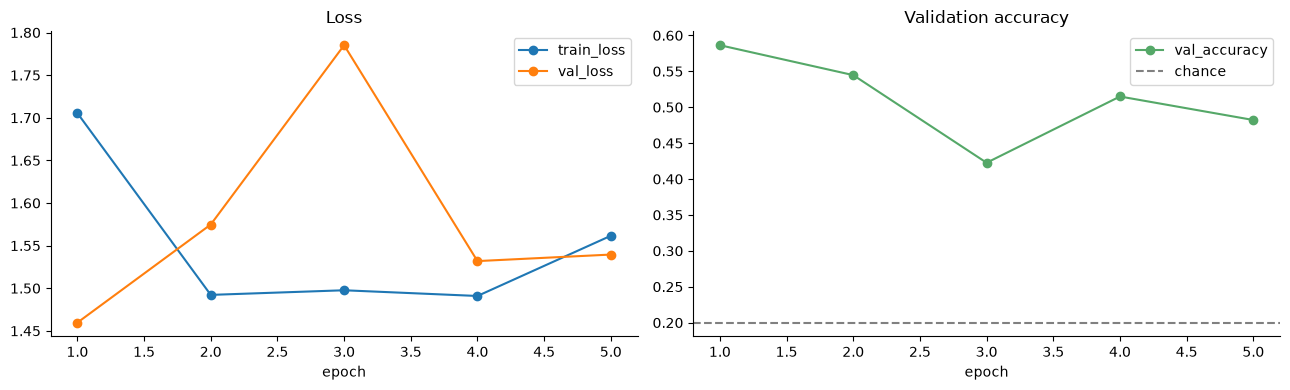

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

curve = pd.DataFrame(history.as_rows())

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))

curve.plot(x="epoch", y=["train_loss", "val_loss"], ax=left, marker="o")
left.set_title("Loss")
left.spines[["top", "right"]].set_visible(False)

curve.plot(x="epoch", y="val_accuracy", ax=right, marker="o", color="#55A868", legend=False)
right.axhline(1 / len(split.class_names), color="grey", linestyle="--", label="chance")
right.set_title("Validation accuracy")
right.legend()
right.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
print(f"best validation accuracy {history.best_val_accuracy:.4f} at epoch {history.best_epoch}")
print(f"stopped early: {history.stopped_early}")

### Fit the calibration temperature and save

The temperature is fitted on validation data only. Notebook 3 measures
whether it generalises to test, and reports what it means for the
abstain threshold that governs when the tool declines to answer.

In [7]:
import numpy as np
import torch
from skinlesion.evaluation.calibration import fit_temperature
from skinlesion.modelling.model import CheckpointMetadata, save_checkpoint

model.eval()
logits, labels = [], []
with torch.no_grad():
    for images, targets in val_loader:
        logits.append(model(images.to(device)).cpu().numpy())
        labels.append(targets.numpy())

temperature = fit_temperature(np.concatenate(logits), np.concatenate(labels))
print(f"fitted temperature: {temperature:.3f}")

checkpoint_path = REPO / config.paths.artifacts_dir / "model.pt"
save_checkpoint(
    model,
    CheckpointMetadata(
        backbone=config.model.backbone,
        image_size=config.model.image_size,
        class_names=split.class_names,
        val_accuracy=history.best_val_accuracy,
        temperature=temperature,
    ),
    checkpoint_path,
)
print(f"saved to {checkpoint_path}")

fitted temperature: 1.290


saved to /Users/cherylt/projects/skin-lesion-id/artifacts/smoke/model.pt
